# Car Price Prediction with Linear Regression

Explore vehicle specifications and build a multiple linear regression model to predict car prices.

This notebook covers data inspection, visual exploration, one-hot encoding, feature scaling, training, and evaluation. Preprocessing is fitted only on the training set through a scikit-learn pipeline. Prices remain in their original units.

**Setup:** Install `requirements.txt`, place `data.csv` beside this notebook, and run the cells from top to bottom.

## 1. Import libraries and load the data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

sns.set_theme(style="whitegrid")
RANDOM_STATE = 20

In [2]:
data_path = Path("data.csv")
df = pd.read_csv(data_path)
df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [3]:
df.info()
print(f"\nRows: {df.shape[0]} | Columns: {df.shape[1]}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   make               193 non-null    object 
 1   fuel-type          193 non-null    object 
 2   aspiration         193 non-null    object 
 3   num-of-doors       193 non-null    object 
 4   body-style         193 non-null    object 
 5   drive-wheels       193 non-null    object 
 6   engine-location    193 non-null    object 
 7   wheel-base         193 non-null    float64
 8   length             193 non-null    float64
 9   width              193 non-null    float64
 10  height             193 non-null    float64
 11  curb-weight        193 non-null    int64  
 12  engine-type        193 non-null    object 
 13  num-of-cylinders   193 non-null    object 
 14  engine-size        193 non-null    int64  
 15  fuel-system        193 non-null    object 
 16  bore               193 non

In [4]:
df.describe()

,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000
mean,98.923834,174.326425,65.893782,53.869948,2561.507772,128.124352,3.330622,3.248860,10.143627,103.481865,5099.740933,25.326425,30.787565,13285.025907
std,6.152409,12.478593,2.137795,2.394770,526.700026,41.590452,0.272385,0.315421,3.977491,37.960107,468.694369,6.387828,6.816910,8089.082886
min,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,94.500000,166.300000,64.100000,52.000000,2145.000000,98.000000,3.150000,3.110000,8.500000,70.000000,4800.000000,19.000000,25.000000,7738.000000
50%,97.000000,173.200000,65.400000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5100.000000,25.000000,30.000000,10245.000000
75%,102.400000,184.600000,66.900000,55.700000,2952.000000,146.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16515.000000
max,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Explore the data

The plots below describe the supplied dataset. Numerical variables include the target `price`; categorical variables describe the manufacturer and vehicle configuration. These plots are descriptive and are not used to tune the model on the test set.

In [5]:
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
numerical_features = [column for column in numerical_columns if column != "price"]

print(f"Categorical features: {len(categorical_columns)}")
print(f"Numerical features: {len(numerical_features)}")

Categorical features: 10
Numerical features: 13


### Categorical distributions

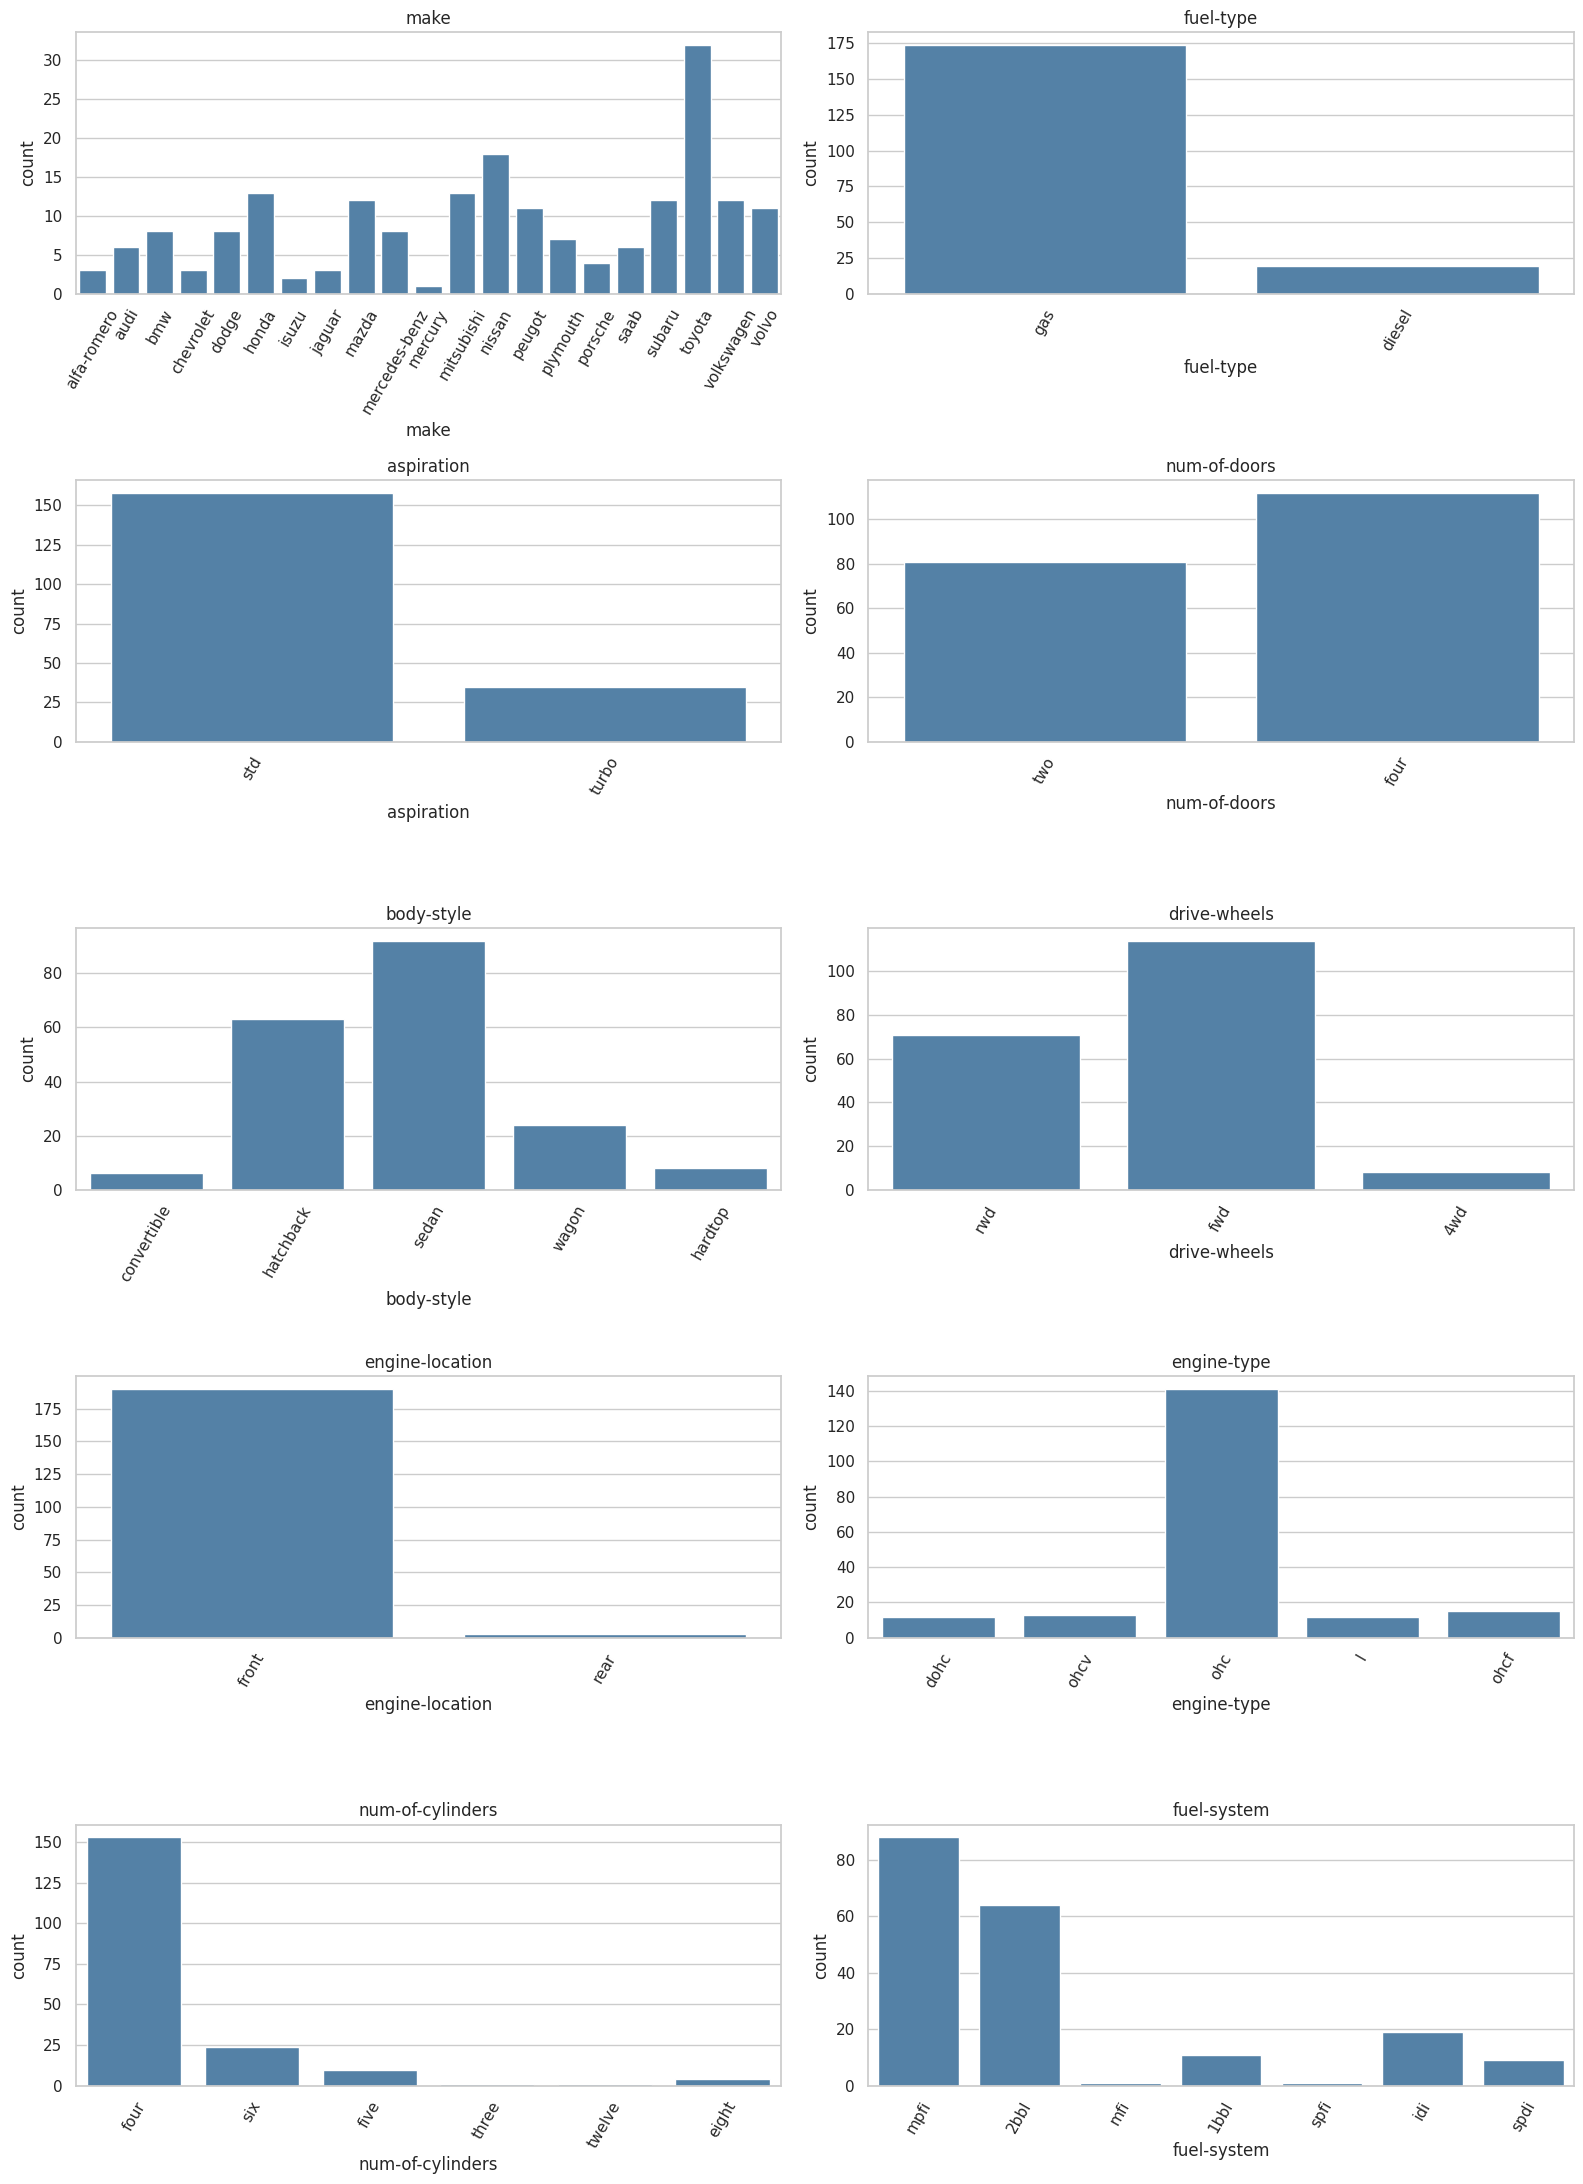

In [6]:
fig, axes = plt.subplots(5, 2, figsize=(16, 22))
for column, ax in zip(categorical_columns, axes.flat):
    sns.countplot(data=df, x=column, ax=ax, color="steelblue")
    ax.set_title(column)
    ax.tick_params(axis="x", labelrotation=60)
plt.tight_layout()
plt.show()

### Numerical distributions

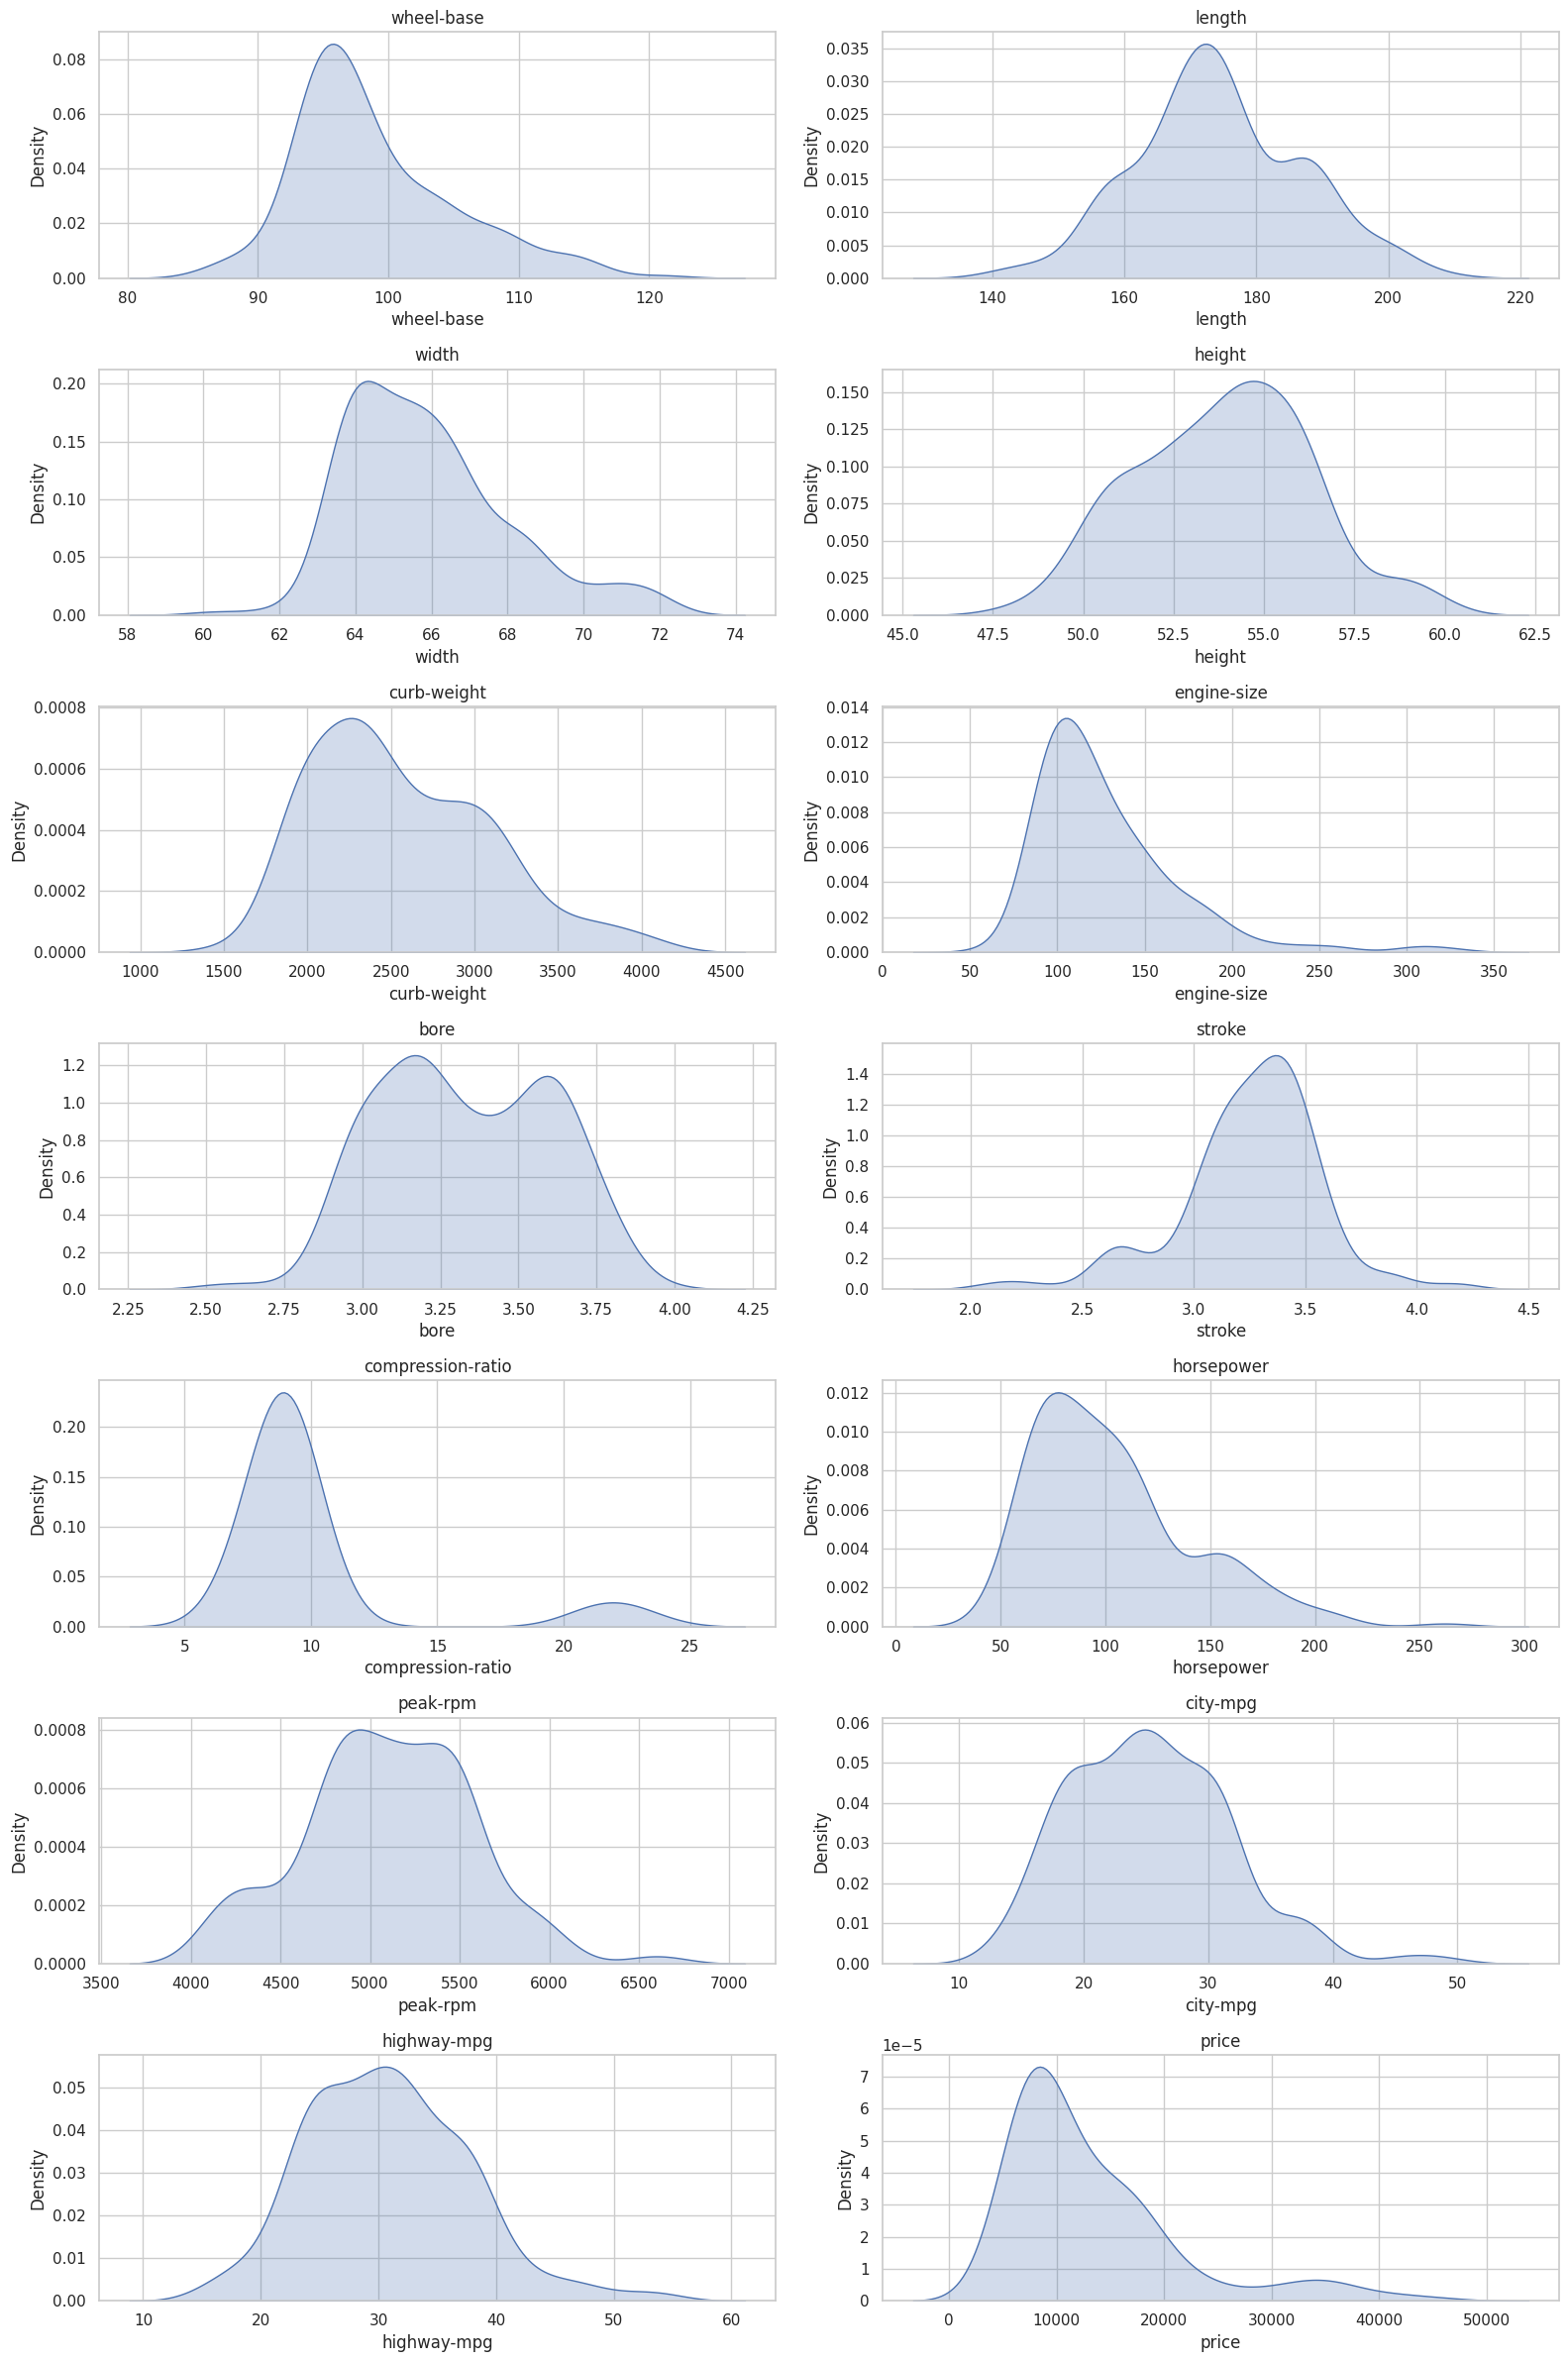

In [7]:
fig, axes = plt.subplots(7, 2, figsize=(16, 24))
for column, ax in zip(numerical_columns, axes.flat):
    sns.kdeplot(data=df, x=column, ax=ax, fill=True)
    ax.set_title(column)
plt.tight_layout()
plt.show()

### Numerical features and price

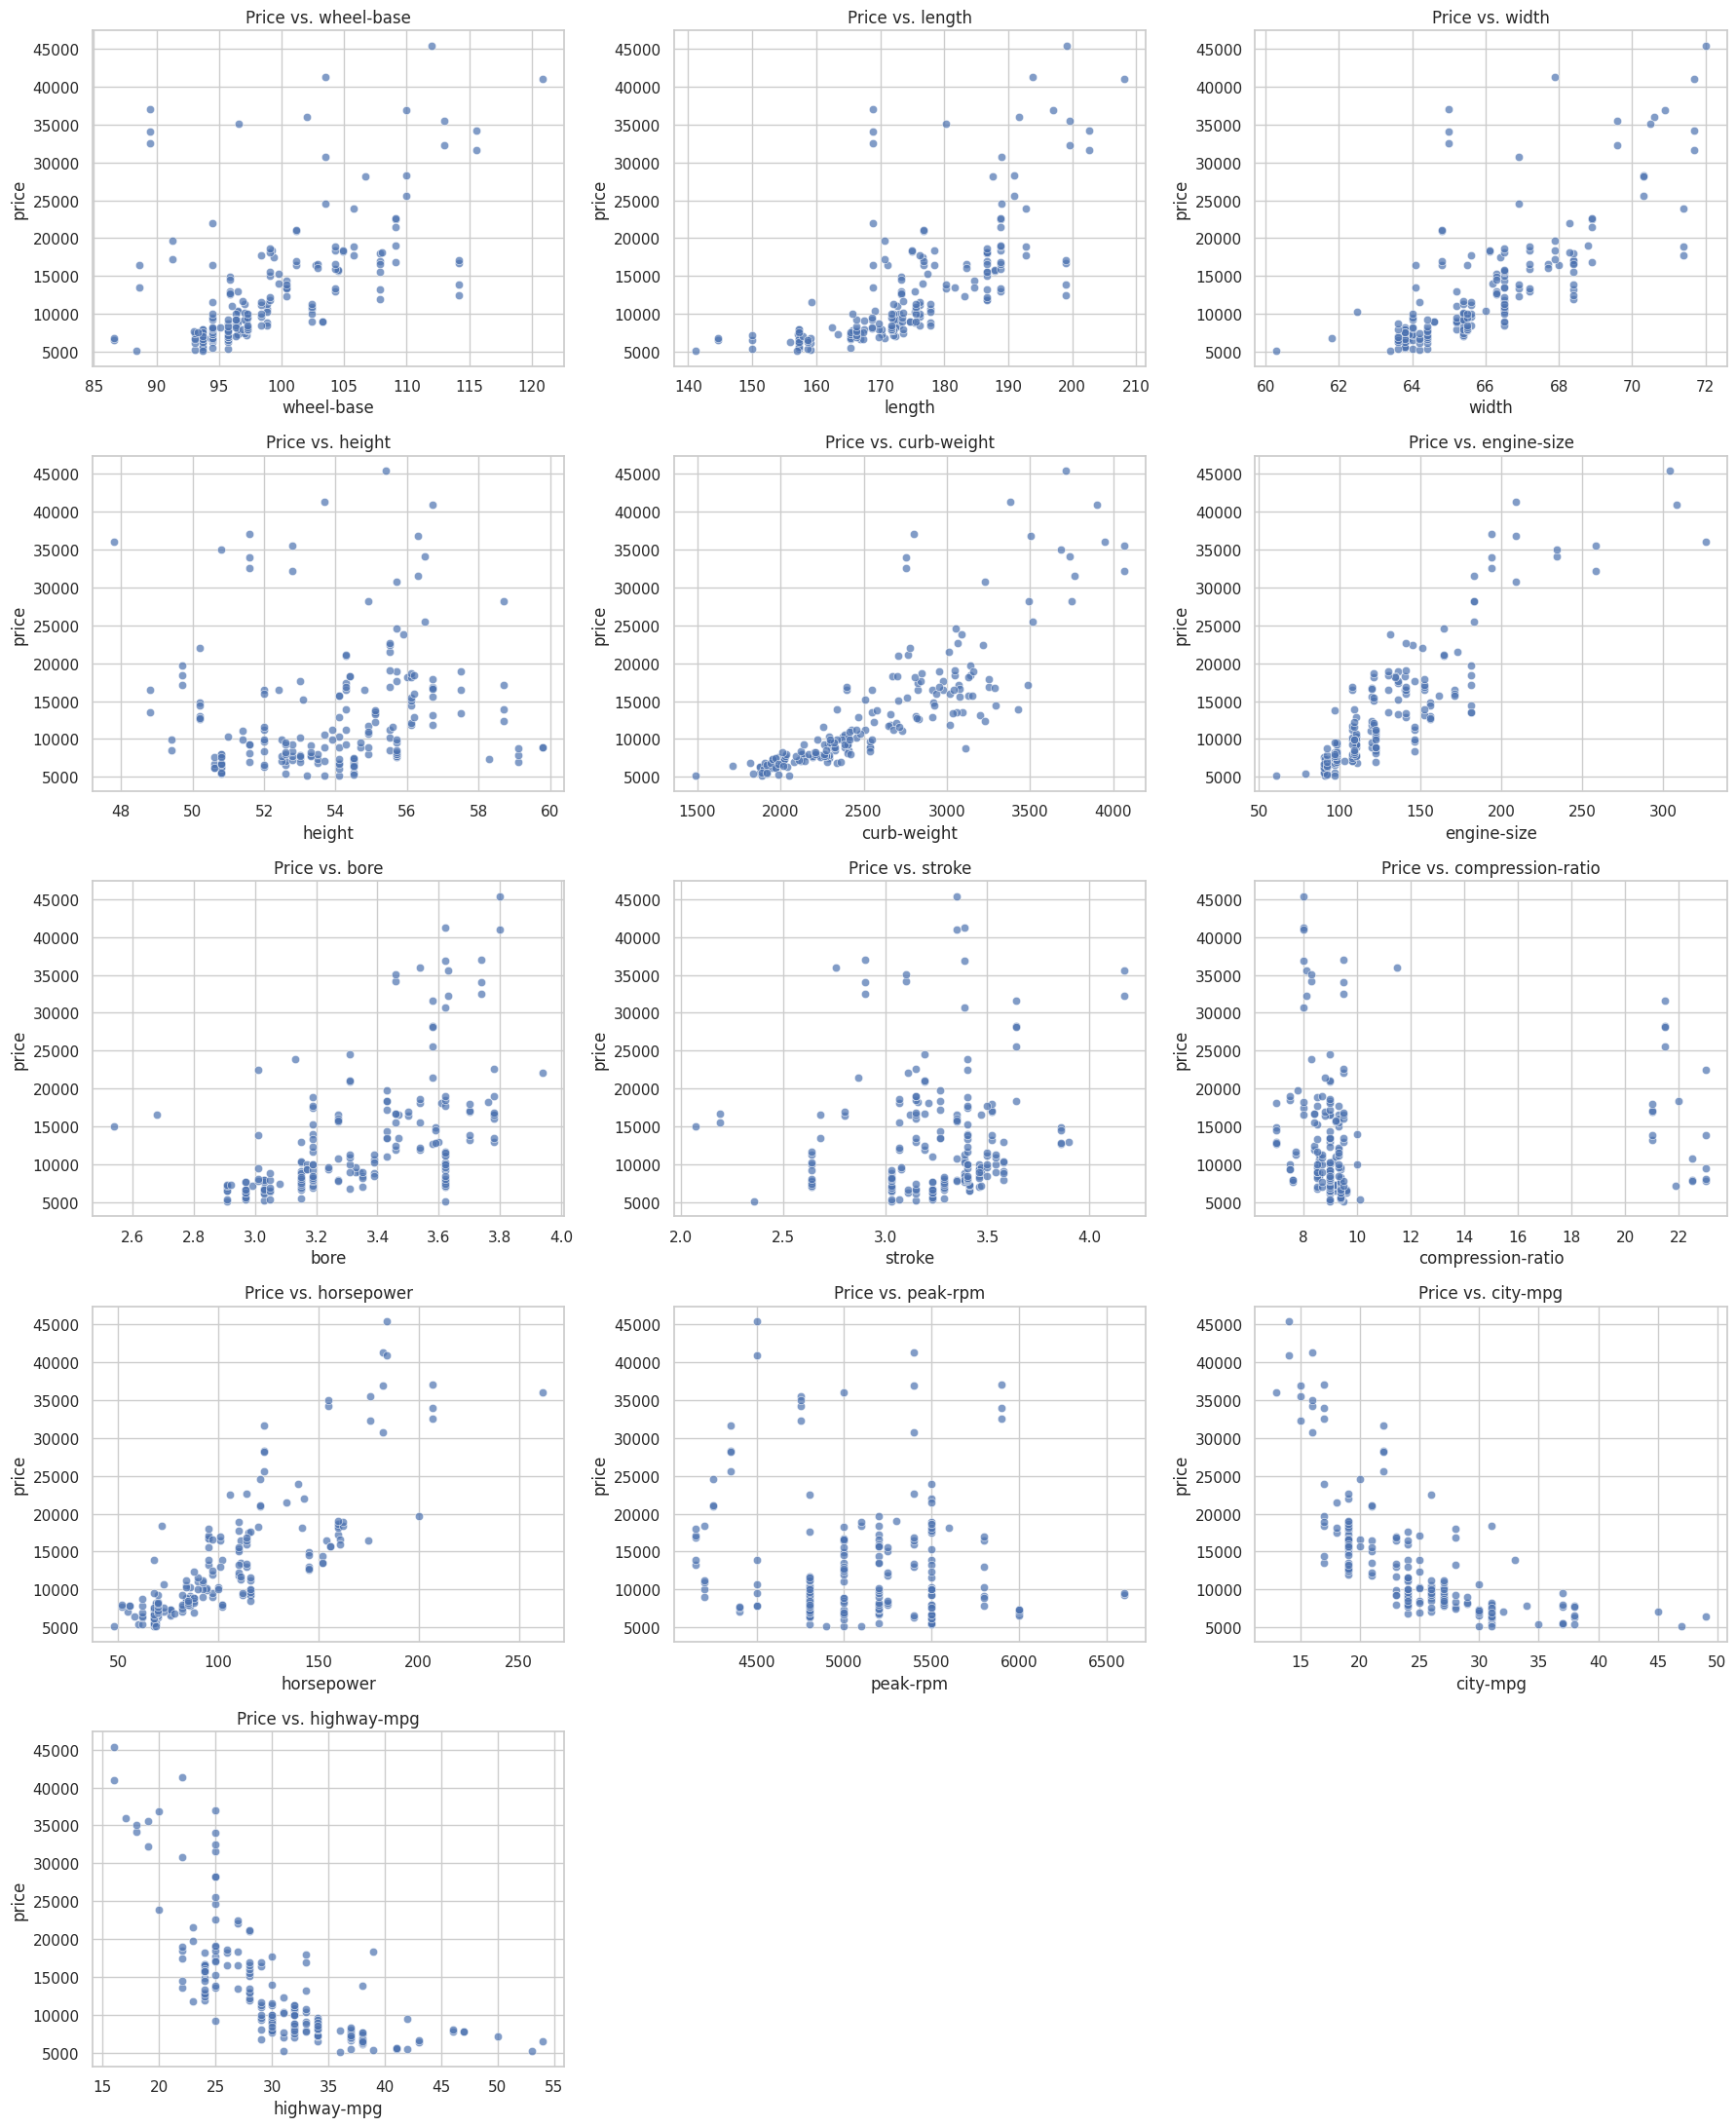

In [8]:
fig, axes = plt.subplots(5, 3, figsize=(18, 22))
for column, ax in zip(numerical_features, axes.flat):
    sns.scatterplot(data=df, x=column, y="price", ax=ax, alpha=0.7)
    ax.set_title(f"Price vs. {column}")
for ax in axes.flat[len(numerical_features):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [9]:
price_correlations = (
    df[numerical_features + ["price"]]
    .corr()["price"]
    .drop("price")
    .sort_values(ascending=False)
)
price_correlations.to_frame("Correlation with price").round(3)

,Correlation with price
engine-size,0.889
curb-weight,0.835
horsepower,0.812
width,0.755
length,0.696
wheel-base,0.585
bore,0.546
height,0.136
stroke,0.096
compression-ratio,0.074


### Categorical features and price

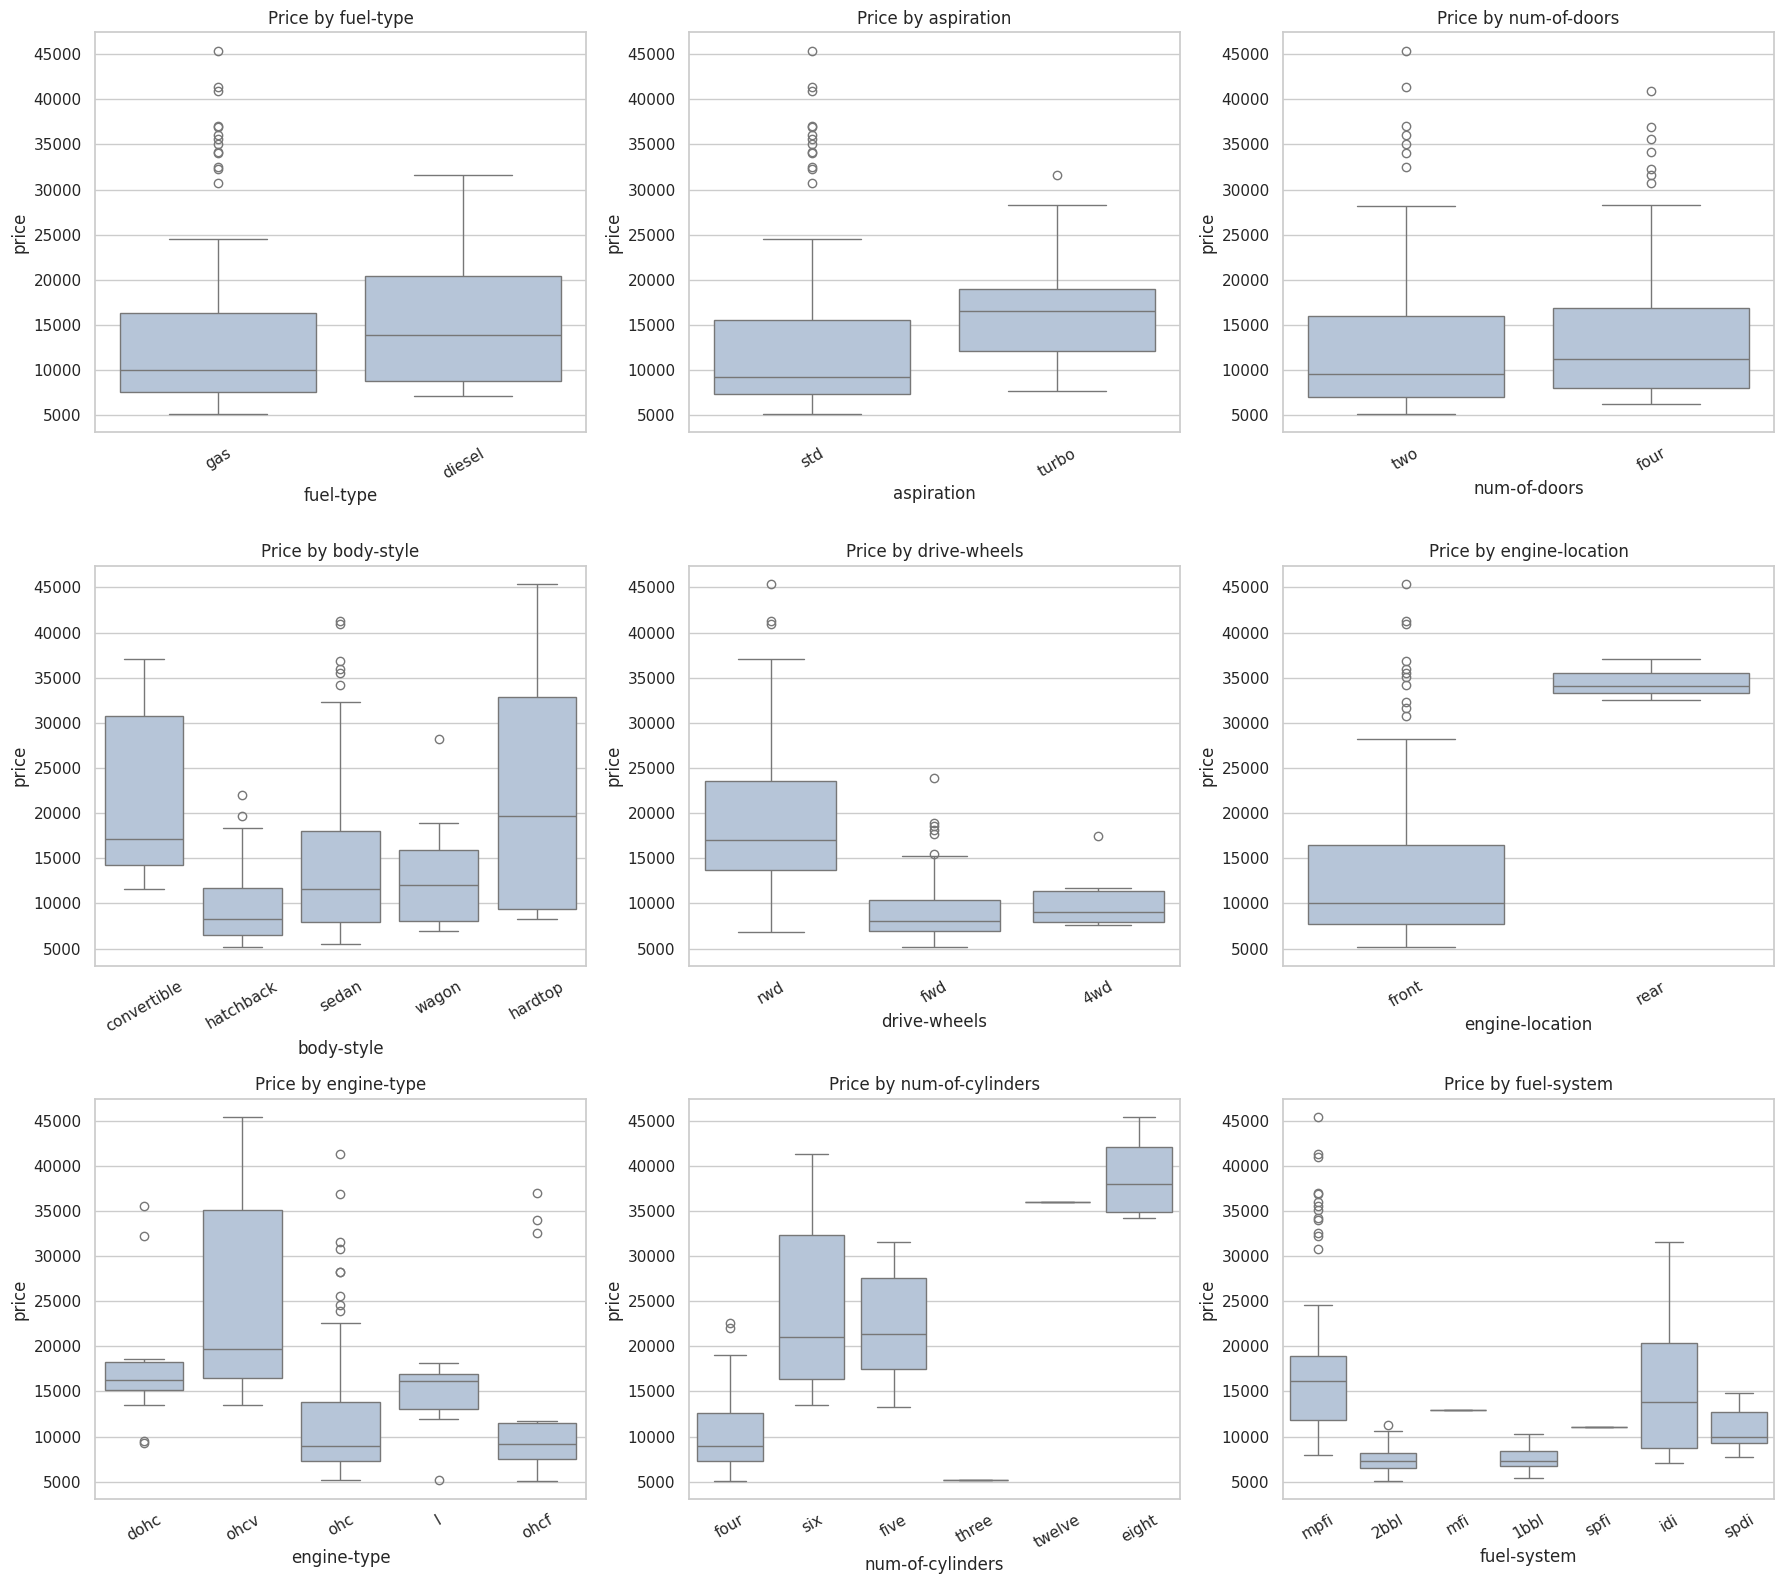

In [10]:
category_features = [column for column in categorical_columns if column != "make"]
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
for column, ax in zip(category_features, axes.flat):
    sns.boxplot(data=df, x=column, y="price", ax=ax, color="lightsteelblue")
    ax.set_title(f"Price by {column}")
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()

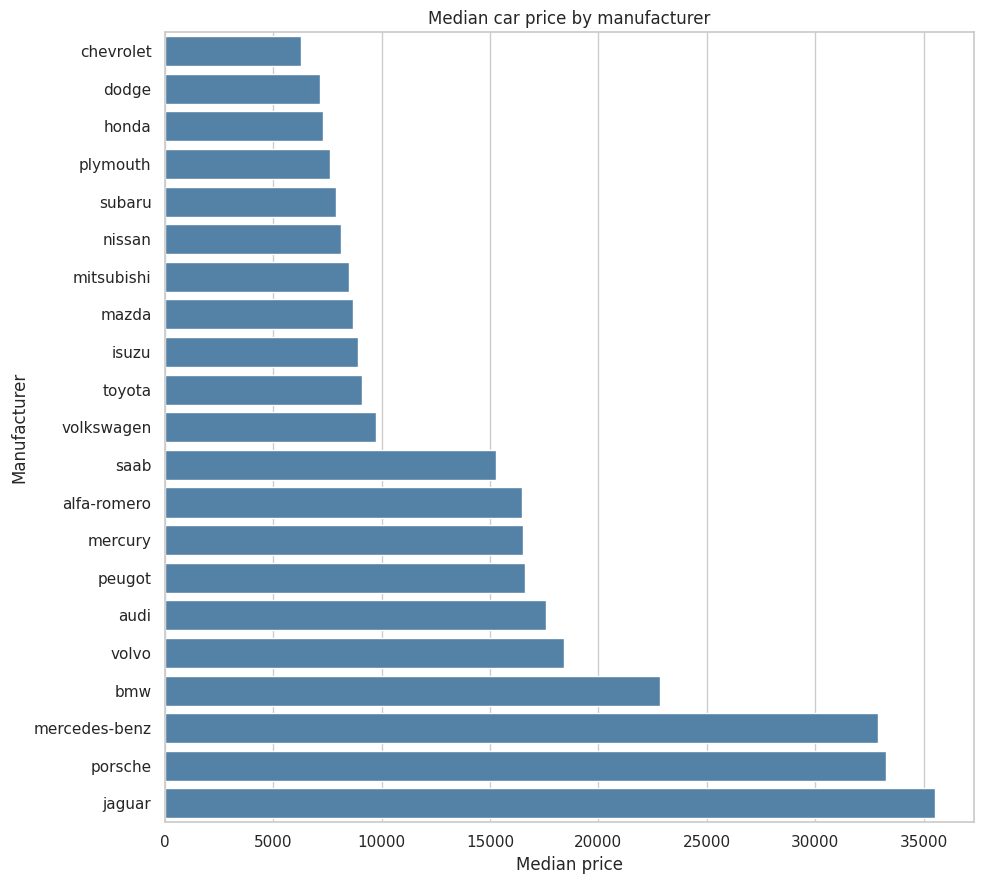

In [11]:
manufacturer_order = df.groupby("make")["price"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 9))
sns.barplot(
    data=df, y="make", x="price", order=manufacturer_order,
    estimator=np.median, errorbar=None, color="steelblue", ax=ax
)
ax.set_title("Median car price by manufacturer")
ax.set_xlabel("Median price")
ax.set_ylabel("Manufacturer")
plt.tight_layout()
plt.show()

## 3. Separate the target and split the data

Keep the target separate from all feature transformations. Reserve 20% of the observations for testing using the original split seed, `random_state=20`.

In [12]:
X = df.drop(columns="price")
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Input attributes before encoding: {X_train.shape[1]}")

Training rows: 154 | Test rows: 39
Input attributes before encoding: 23


## 4. Build the preprocessing and regression pipeline

- **Numerical features:** `MinMaxScaler` learns each feature's minimum and maximum from the training set.
- **Categorical features:** `OneHotEncoder` learns the training categories and drops one reference category per feature, avoiding the redundant full set of indicator columns with an intercept. Unseen categories can be processed with `handle_unknown="ignore"`.
- **Regression:** `LinearRegression` fits the transformed training inputs.

The pipeline applies the same fitted transformations when predicting. It does not transform `price` or modify the original dataframe. Scaling is included as a consistent preprocessing step; ordinary least-squares regression does not require it.

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", MinMaxScaler(), numeric_features),
        ("categorical", OneHotEncoder(
            drop="first", handle_unknown="ignore", sparse_output=False
        ), categorical_features),
    ]
)

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regression", LinearRegression()),
])

model.fit(X_train, y_train)
print("Preprocessing and regression fitted on the training set.")
print(f"Encoded input features: {len(model.named_steps['preprocessing'].get_feature_names_out())}")

Preprocessing and regression fitted on the training set.
Encoded input features: 58


## 5. Predict and evaluate

Evaluate the fitted model on the held-out rows. A mean-price baseline predicts the training target's mean for every test car, providing context for the regression results.

R² measures fit relative to the test target's mean. MAE and RMSE are in the original price units; MSE is in squared price units. These results describe this fixed 39-row test split.

In [14]:
y_pred = model.predict(X_test)

prediction_comparison = pd.DataFrame({
    "Actual price": y_test,
    "Predicted price": y_pred,
})
prediction_comparison["Residual"] = (
    prediction_comparison["Actual price"] - prediction_comparison["Predicted price"]
)
prediction_comparison["Absolute error"] = prediction_comparison["Residual"].abs()
prediction_comparison.head(10).round(2)

,Actual price,Predicted price,Residual,Absolute error
28,6479,2616.86,3862.14,3862.14
161,8948,8677.54,270.46,270.46
59,28248,28395.36,-147.36,147.36
13,24565,23552.41,1012.59,1012.59
51,8845,11527.56,-2682.56,2682.56
132,9233,9278.58,-45.58,45.58
180,13845,11734.38,2110.62,2110.62
127,7053,5908.73,1144.27,1144.27
104,16695,12507.80,4187.20,4187.20
126,5118,6426.65,-1308.65,1308.65


In [15]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
    }

results = pd.DataFrame({
    "Mean-price baseline": regression_metrics(y_test, baseline_pred),
    "Linear regression": regression_metrics(y_test, y_pred),
}).T
results.round(4)

,R2,MAE,MSE,RMSE
Mean-price baseline,-0.0450,7329.372,1.011199e+08,10055.8391
Linear regression,0.8715,2396.376,1.242939e+07,3525.5340


### Prediction and residual plots

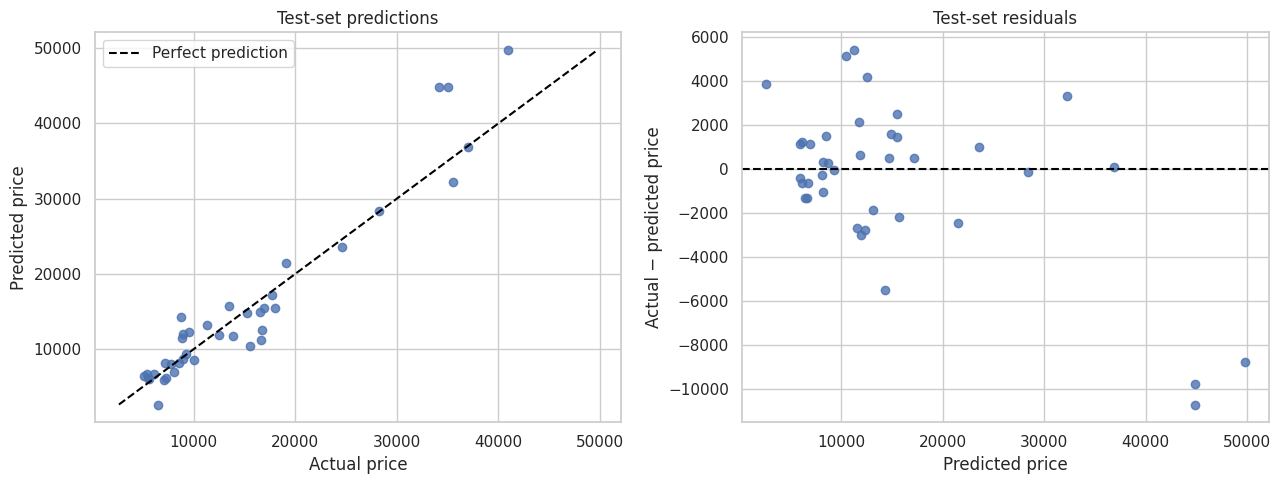

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.8)
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
axes[0].plot([lower, upper], [lower, upper], "--", color="black", label="Perfect prediction")
axes[0].set(xlabel="Actual price", ylabel="Predicted price", title="Test-set predictions")
axes[0].legend()

axes[1].scatter(y_pred, y_test - y_pred, alpha=0.8)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set(xlabel="Predicted price", ylabel="Actual − predicted price", title="Test-set residuals")

plt.tight_layout()
plt.show()

## 6. Predict from vehicle attributes

The fitted pipeline accepts a dataframe with the same 23 input columns as `X_train`. The example below reuses one held-out car to demonstrate inference.

In [17]:
example_car = X_test.iloc[[0]]
example_prediction = model.predict(example_car)[0]
print(f"Predicted price: {example_prediction:,.2f}")
print(f"Actual price: {y_test.iloc[0]:,.2f}")

Predicted price: 2,616.86
Actual price: 6,479.00


## Dataset attribution

The supplied CSV's column names and sampled records match the [UCI Automobile dataset](https://archive.ics.uci.edu/dataset/10/automobile), indicating a prepared version of that source. This project uses the supplied 193-row file.

Schlimmer, J. (1985). *Automobile* [Dataset]. UCI Machine Learning Repository. [doi:10.24432/C5B01C](https://doi.org/10.24432/C5B01C). UCI distributes the original dataset under CC BY 4.0.

## References
[Kaggle_1](https://www.kaggle.com/code/pulkitmittal15/car-price-prediction-project)

[Kaggle_2](https://www.kaggle.com/code/jacopoferretti/predicting-car-prices-with-regression-pipelines)

[Kaggle_3](https://www.kaggle.com/code/anshulsingh19/car-price-prediction-multiple-linear-regression)

[Kaggle_4](https://www.kaggle.com/code/samanyuk/car-price-using-a-simple-random-forest)

[Kaggle_5](https://www.kaggle.com/code/gadigevishalsai/car-sales-price-prediction-eda-regression)

[github](https://github.com/roshancyriacmathew/Car-price-prediction-using-Linear-regression-Machine-Learning-Project)

[pandas](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)

[sklearn](https://scikit-learn.org/stable/getting_started.html)

[LabelEncoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html)

[MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html)

[get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)

[medium](https://medium.com/data-folks-indonesia/powering-up-your-pandas-part-ii-label-encoding-and-one-hot-encoding-dac0fce045da)

### Pipeline documentation

- [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [Avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)